# Первичный анализ MNIST

Направление: Computer Vision.

Задача: классификация изображений рукописных цифр от 0 до 9.

Вход: изображение 28 × 28 пикселей в оттенках серого.
Выход: предсказанный класс цифры.
Пользователь: приложение оцифровки форм.

Цель исследования: проверить структуру данных, распределение классов
и целостность архива. Обучение модели на данном этапе не выполняется.

from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

dataset_path = PROJECT_ROOT / "data" / "mnist.npz"

with np.load(dataset_path, allow_pickle=False) as dataset:
    x_train = dataset["x_train"]
    y_train = dataset["y_train"]
    x_test = dataset["x_test"]
    y_test = dataset["y_test"]

print("Обучающие изображения:", x_train.shape)
print("Обучающие метки:", y_train.shape)
print("Тестовые изображения:", x_test.shape)
print("Тестовые метки:", y_test.shape)
print("Тип пикселей:", x_train.dtype)
print("Диапазон значений:", x_train.min(), x_train.max())
print("Размер архива, байт:", dataset_path.stat().st_size)

assert x_train.shape == (60000, 28, 28)
assert x_test.shape == (10000, 28, 28)
assert y_train.shape == (60000,)
assert y_test.shape == (10000,)
assert set(np.unique(y_train)) == set(range(10))
assert set(np.unique(y_test)) == set(range(10))

In [10]:
distribution = pd.DataFrame({
    "train": pd.Series(y_train).value_counts().sort_index(),
    "test": pd.Series(y_test).value_counts().sort_index(),
})

distribution.index.name = "Класс"
distribution["total"] = distribution["train"] + distribution["test"]
distribution["train_share_percent"] = (
    distribution["train"] / len(y_train) * 100
).round(2)

display(distribution)

distribution.to_csv(
    PROJECT_ROOT / "reports" / "class_distribution.csv"
)

,train,test,total,train_share_percent
Класс,,,,
0,5923,980,6903,9.87
1,6742,1135,7877,11.24
2,5958,1032,6990,9.93
3,6131,1010,7141,10.22
4,5842,982,6824,9.74
5,5421,892,6313,9.04
6,5918,958,6876,9.86
7,6265,1028,7293,10.44
8,5851,974,6825,9.75


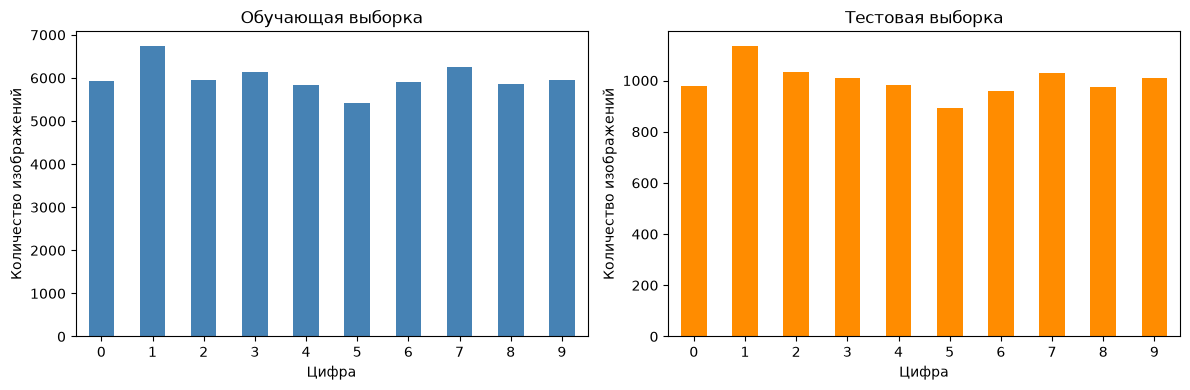

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

distribution["train"].plot.bar(
    ax=axes[0], color="steelblue", rot=0
)
axes[0].set_title("Обучающая выборка")
axes[0].set_xlabel("Цифра")
axes[0].set_ylabel("Количество изображений")

distribution["test"].plot.bar(
    ax=axes[1], color="darkorange", rot=0
)
axes[1].set_title("Тестовая выборка")
axes[1].set_xlabel("Цифра")
axes[1].set_ylabel("Количество изображений")

plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "reports" / "class_distribution.png",
    dpi=150
)
plt.show()

In [12]:
counts = distribution["train"]
ratio = counts.max() / counts.min()

print("Наибольший класс:", counts.idxmax())
print("Количество объектов:", counts.max())
print("Наименьший класс:", counts.idxmin())
print("Количество объектов:", counts.min())
print("Разница:", counts.max() - counts.min())
print(f"Отношение максимума к минимуму: {ratio:.3f}")

Наибольший класс: 1
Количество объектов: 6742
Наименьший класс: 5
Количество объектов: 5421
Разница: 1321
Отношение максимума к минимуму: 1.244


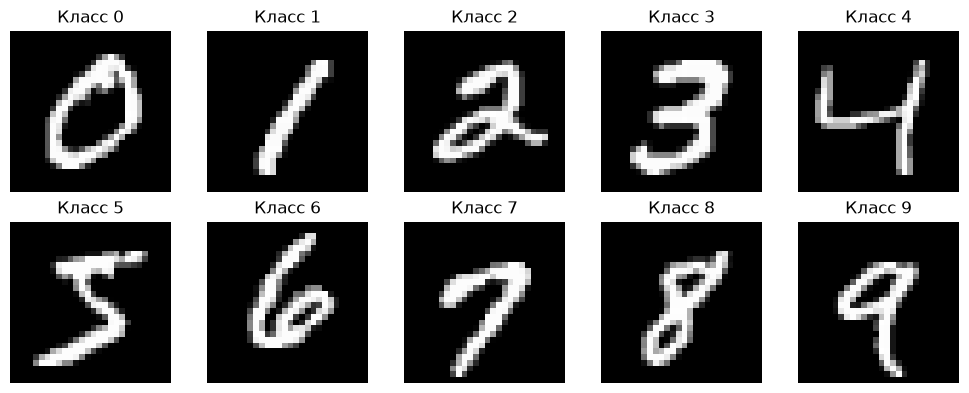

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for digit, ax in enumerate(axes.flat):
    index = np.flatnonzero(y_train == digit)[0]
    ax.imshow(x_train[index], cmap="gray")
    ax.set_title(f"Класс {digit}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
sha256 = hashlib.sha256()

with dataset_path.open("rb") as dataset_file:
    for block in iter(lambda: dataset_file.read(1024 * 1024), b""):
        sha256.update(block)

actual_hash = sha256.hexdigest()

reference_line = (
    PROJECT_ROOT / "reports" / "dataset.sha256"
).read_text().strip()

expected_hash = reference_line.split()[0]

print("Файл:", dataset_path.name)
print("Эталонный SHA256:", expected_hash)
print("Вычисленный SHA256:", actual_hash)
print("Совпадение:", actual_hash == expected_hash)

assert actual_hash == expected_hash, "Целостность датасета нарушена"

Файл: mnist.npz
Эталонный SHA256: 731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1
Вычисленный SHA256: 731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1
Совпадение: True


## Вывод

MNIST содержит 70 000 изображений, разделённых на обучающую
и тестовую выборки. Представлены все десять классов.

Количество объектов между классами различается, однако сильного
дисбаланса не наблюдается. Точные значения отношения крупнейшего
класса к наименьшему приведены выше.

При дисбалансе модель может чаще выбирать распространённые классы.
В последующих работах наряду с accuracy целесообразно оценивать
macro-F1, полноту по классам и матрицу ошибок.

Искусственная балансировка на данном этапе не выполнялась.
Тестовая выборка сохраняется отдельно и не используется для обучения.

SHA256 архива сравнен с отдельно сохранённым эталоном.
Результат проверки представлен выше.